# PraNet: Raw 与 99.5%+FMM 完整训练/推理

默认不训练，直接读取当前权重文件夹中统一命名的Raw/FMM最佳权重进行对应推理。设置 `RUN_TRAINING=True` 可从图片文件夹重新训练并生成两套独立最佳权重。


In [1]:
# 基础环境与依赖
import os
os.environ.setdefault("SM_FRAMEWORK", "tf.keras")

import h5py
import gc
import math
import re
from pathlib import Path

import cv2
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, AveragePooling2D, Conv2DTranspose,
    BatchNormalization, Activation, ReLU, UpSampling2D, Concatenate,
    Dropout, LeakyReLU, concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.initializers import he_normal

import segmentation_models as sm
sm.set_framework('tf.keras')


Segmentation Models: using `tf.keras` framework.


In [2]:
# =========================
# 运行配置
# =========================
MODEL_NAME = 'PraNet'
MODEL_DIR_NAME = 'PraNet'

# 默认只使用历史权重推理。需要重新训练时改为 True。
RUN_TRAINING = False

# 训练保存与推理读取统一使用固定文件名：
# 模型名称_img_bestweight.h5
# 模型名称_99.5+FMM_bestweight.h5

IMAGE_HEIGHT = 288
IMAGE_WIDTH = 384
IMAGE_SIZE = (IMAGE_WIDTH, IMAGE_HEIGHT)
PERCENTILE = 99.5
INPAINT_RADIUS = 10
JPEG_QUALITY = 95
PREDICTION_THRESHOLD = 0.5
BOUNDARY_DILATION_RATIO = 0.02

EPOCHS = 300
TRAIN_BATCH_SIZE = 2
# 与原Notebook的model.evaluate默认值一致；表格与可视化共用该次批量前向缓存。
INFERENCE_BATCH_SIZE = 32
# 原Notebook的model.evaluate未指定batch_size，Keras 2.9默认按32张分组计算指标。
METRIC_BATCH_SIZE = 32
SEED = 42

LOAD_BY_NAME = False  # 仅保留为说明；实际始终严格完整载入
USE_SM_TRAINING_LOSS = True
USE_SM_EVALUATION_IOU = True

# 可视化选择必须在评估前设置，便于缓存同一次前向的对应样本。
VIS_DATASET = "CVC-ColonDB"
VIS_SAMPLE_INDEX = 48

TEST_DATASETS = [
    "CVC-300",
    "CVC-ClinicDB",
    "CVC-ColonDB",
    "ETIS-LaribPolypDB",
    "Kvasir",
]


## 模型结构（复制自原Notebook）


In [3]:
# 1. 定义 RFB_modified 模块
class RFB_modified(tf.keras.layers.Layer):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        # 四个并行分支
        self.branch0 = models.Sequential([
            Conv2D(out_channels, 1, padding='same'),
            BatchNormalization(), ReLU()
        ])
        self.branch1 = models.Sequential([
            Conv2D(out_channels, 1, padding='same'),
            BatchNormalization(), ReLU(),
            Conv2D(out_channels, (1,3), padding='same'),
            BatchNormalization(), ReLU(),
            Conv2D(out_channels, (3,1), padding='same'),
            BatchNormalization(), ReLU(),
            Conv2D(out_channels, 3, padding='same', dilation_rate=3),
            BatchNormalization(), ReLU()
        ])
        self.branch2 = models.Sequential([
            Conv2D(out_channels, 1, padding='same'),
            BatchNormalization(), ReLU(),
            Conv2D(out_channels, (1,5), padding='same'),
            BatchNormalization(), ReLU(),
            Conv2D(out_channels, (5,1), padding='same'),
            BatchNormalization(), ReLU(),
            Conv2D(out_channels, 3, padding='same', dilation_rate=5),
            BatchNormalization(), ReLU()
        ])
        self.branch3 = models.Sequential([
            Conv2D(out_channels, 1, padding='same'),
            BatchNormalization(), ReLU(),
            Conv2D(out_channels, (1,7), padding='same'),
            BatchNormalization(), ReLU(),
            Conv2D(out_channels, (7,1), padding='same'),
            BatchNormalization(), ReLU(),
            Conv2D(out_channels, 3, padding='same', dilation_rate=7),
            BatchNormalization(), ReLU()
        ])
        # 融合与残差
        self.conv_cat = Conv2D(out_channels, 3, padding='same')
        self.bn_cat   = BatchNormalization()
        self.relu_cat = ReLU()
        self.conv_res = Conv2D(out_channels, 1, padding='same')
        self.bn_res   = BatchNormalization()
        self.relu     = ReLU()

    def call(self, x):
        x0 = self.branch0(x)
        x1 = self.branch1(x)
        x2 = self.branch2(x)
        x3 = self.branch3(x)
        x_cat = Concatenate()([x0, x1, x2, x3])
        x_cat = self.conv_cat(x_cat)
        x_cat = self.bn_cat(x_cat)
        x_cat = self.relu_cat(x_cat)
        res   = self.conv_res(x)
        res   = self.bn_res(res)
        return self.relu(x_cat + res)

# 2. 定义 Aggregation 模块
class Aggregation(tf.keras.layers.Layer):
    def __init__(self, channel):
        super().__init__()
        self.conv_upsample1 = Conv2D(channel, 3, padding='same')
        self.conv_upsample2 = Conv2D(channel, 3, padding='same')
        self.conv_upsample3 = Conv2D(channel, 3, padding='same')
        self.conv_concat2   = Conv2D(channel, 3, padding='same')
        self.conv_concat3   = Conv2D(channel, 3, padding='same')
        self.conv4          = Conv2D(channel, 3, padding='same')
        self.conv5          = Conv2D(1,       1, padding='same')

    def call(self, x1, x2, x3):
        x2_1 = self.conv_upsample1(UpSampling2D(2)(x1)) * x2
        x3_1 = self.conv_upsample2(UpSampling2D(2)(x2_1)) * \
               self.conv_upsample3(UpSampling2D(4)(x1)) * x3
        x2_2 = Concatenate()([x2_1, UpSampling2D(2)(x1)])
        x2_2 = self.conv_concat2(x2_2)
        x3_2 = Concatenate()([x3_1, UpSampling2D(2)(x2_2)])
        x3_2 = self.conv_concat3(x3_2)
        x    = self.conv4(x3_2)
        return self.conv5(x)

# 3. 定义 ReverseAttention 模块
class ReverseAttention(tf.keras.layers.Layer):
    def __init__(self, in_channels):
        super().__init__()
        self.conv1 = Conv2D(in_channels, 3, padding='same')
        self.conv2 = Conv2D(in_channels, 3, padding='same')
        self.conv3 = Conv2D(1,           3, padding='same')

    def call(self, x, y):
        # 将粗预测 y 缩放到 x 的尺寸
        y_resized = tf.image.resize(y, tf.shape(x)[1:3], method='bilinear')
        reverse   = 1 - tf.sigmoid(y_resized)
        x_att     = x * reverse
        x_att     = self.conv1(x_att)
        x_att     = self.conv2(x_att)
        x_att     = self.conv3(x_att)
        return x_att + y_resized

# 4. 构建 ResNet50 主干
def build_backbone(input_shape):
    base = tf.keras.applications.ResNet50(
        include_top=False,
        weights='imagenet' if RUN_TRAINING else None,
        input_shape=input_shape
    )
    # C2,C3,C4,C5 分别对应下采样 4,8,16,32 倍之后的特征图
    return models.Model(
        inputs=base.input,
        outputs=[
            base.get_layer('conv2_block3_out').output,
            base.get_layer('conv3_block4_out').output,
            base.get_layer('conv4_block6_out').output,
            base.get_layer('conv5_block3_out').output
        ]
    )

# 5. 构建完整 PraNet 模型，动态 resize 输出
def build_pranet(input_shape=(288, 384, 3), channel=32):
    inputs   = Input(shape=input_shape)
    c2, c3, c4, c5 = build_backbone(input_shape)(inputs)

    r2 = RFB_modified(512, channel)(c2)
    r3 = RFB_modified(1024, channel)(c3)
    r4 = RFB_modified(2048, channel)(c4)
    agg = Aggregation(channel)(r4, r3, r2)

    ra4 = ReverseAttention(2048)(c4, agg)
    ra3 = ReverseAttention(1024)(c3, ra4)
    ra2 = ReverseAttention(512,)(c2, ra3)

    # 动态 resize：直接将所有输出对齐到原始输入大小
    target_size = tf.shape(inputs)[1:3]
    agg_up = tf.image.resize(agg, target_size, method='bilinear')
    ra4_up = tf.image.resize(ra4, target_size, method='bilinear')
    ra3_up = tf.image.resize(ra3, target_size, method='bilinear')
    ra2_up = tf.image.resize(ra2, target_size, method='bilinear')

    outputs = [
        tf.keras.activations.sigmoid(ra2_up)
    ]

    return models.Model(inputs=inputs, outputs=outputs)

def build_model():
    return build_pranet(input_shape=(288, 384, 3), channel=32)


In [4]:
# =========================
# 损失函数与原评价指标
# =========================
def bce_jaccard_loss(y_true, y_pred, smooth=1e-7, alpha=0.5):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f + y_pred_f) - intersection
    jaccard = (intersection + smooth) / (union + smooth)
    jaccard_loss = 1 - jaccard
    return alpha * bce + (1 - alpha) * jaccard_loss


def dice_score(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    denominator = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    return (2.0 * intersection + smooth) / (denominator + smooth)


def iou_score(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)


def compile_for_training(model):
    if USE_SM_TRAINING_LOSS:
        model.compile(
            optimizer='Adam',
            loss=sm.losses.bce_jaccard_loss,
            metrics=[sm.metrics.iou_score],
        )
    else:
        model.compile(
            optimizer='Adam',
            loss=bce_jaccard_loss,
            metrics=[iou_score],
        )
    return model


def compile_for_evaluation(model):
    # 严格沿用原Notebook最终历史权重评价时选择的IoU定义。
    evaluation_iou = sm.metrics.iou_score if USE_SM_EVALUATION_IOU else iou_score
    model.compile(
        optimizer='Adam',
        loss=bce_jaccard_loss,
        metrics=[dice_score, evaluation_iou],
    )
    return model


In [5]:
# =========================
# 项目路径、Raw/FMM处理与文件夹数据流
# =========================
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


# def find_project_root(start=None):
#     start = Path.cwd().resolve() if start is None else Path(start).resolve()
#     for candidate in (start, *start.parents):
#         if (candidate / "Data" / "Test").is_dir() and (candidate / "best weight").is_dir():
#             return candidate
#     raise FileNotFoundError("未找到同时包含 Data/Test 与 best weight 的项目根目录")


PROJECT_ROOT = Path("D:/WJY/paper1")  # 推荐使用正斜杠，Path 会自动处理
TRAIN_IMAGE_DIR = PROJECT_ROOT / "Data" / "Train" / "img"
TRAIN_MASK_DIR = PROJECT_ROOT / "Data" / "Train" / "masks"
TRAIN_INDEX_FILE = PROJECT_ROOT / "code" / "Train.txt"
VAL_INDEX_FILE = PROJECT_ROOT / "code" / "Val.txt"
WEIGHT_MODEL_DIR = PROJECT_ROOT / "best weight" / "2.different mode" / MODEL_DIR_NAME

print("PROJECT_ROOT:", PROJECT_ROOT)
print("MODEL:", MODEL_NAME)



def list_image_names(image_dir):
    # 保留历史H5制作时的os.listdir顺序；同名配对避免图像与mask错位。
    names = [
        name for name in os.listdir(image_dir)
        if (Path(image_dir) / name).is_file() and Path(name).suffix.lower() in IMAGE_EXTENSIONS
    ]
    if not names:
        raise FileNotFoundError(f"图像目录为空: {image_dir}")
    return names


def validate_pairs(image_dir, mask_dir, names):
    missing = [name for name in names if not (Path(mask_dir) / name).is_file()]
    if missing:
        raise FileNotFoundError(f"{mask_dir} 缺少 {len(missing)} 个同名mask，例如: {missing[:5]}")


def read_raw_image(image_path):
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"无法读取图像: {image_path}")
    image = cv2.resize(image, IMAGE_SIZE)
    # 历史H5制作流程在OpenCV读取后执行[..., ::-1]，模型实际使用RGB输入。
    image = image[..., ::-1]
    return image.astype(np.float32) / 255.0


def create_highlight_mask(image_path, percentile=PERCENTILE):
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f"无法读取灰度图: {image_path}")
    threshold = np.percentile(gray, percentile)
    _, highlight_mask = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)
    return highlight_mask


def read_fmm_image(image_path):
    # 严格沿用原高光修复代码：99.5%阈值mask + 0.6倍缩放 + TELEA/FMM半径10。
    src = cv2.imread(str(image_path))
    if src is None:
        raise ValueError(f"无法读取图像: {image_path}")
    highlight_mask = create_highlight_mask(image_path)

    resized_src = cv2.resize(
        src, None, fx=0.6, fy=0.6, interpolation=cv2.INTER_CUBIC
    )
    resized_highlight_mask = cv2.resize(
        highlight_mask, None, fx=0.6, fy=0.6, interpolation=cv2.INTER_CUBIC
    )
    restored = cv2.inpaint(
        resized_src, resized_highlight_mask, INPAINT_RADIUS, cv2.INPAINT_TELEA
    )
    restored = cv2.resize(restored, IMAGE_SIZE)

    # 原流程将修复结果保存为JPG后再读取。这里在内存中模拟相同JPG往返，不产生中间文件。
    ok, encoded = cv2.imencode(
        ".jpg", restored, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY]
    )
    if not ok:
        raise RuntimeError(f"FMM结果JPG编码失败: {image_path}")
    restored = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    # 与历史FMM-H5保持一致：JPG重新读取后由BGR转换为RGB。
    restored = restored[..., ::-1]
    return restored.astype(np.float32) / 255.0


def read_segmentation_mask(mask_path):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"无法读取mask: {mask_path}")
    mask = cv2.resize(mask, IMAGE_SIZE)
    return (mask / 255).reshape(IMAGE_HEIGHT, IMAGE_WIDTH, 1)


class FolderSegmentationSequence(keras.utils.Sequence):
    def __init__(
        self, image_dir, mask_dir, names, indexes, batch_size,
        condition="raw", shuffle=False, seed=SEED
    ):
        super().__init__()
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.names = list(names)
        self.indexes = np.asarray(indexes, dtype=int)
        self.batch_size = int(batch_size)
        self.condition = condition
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.order = np.arange(len(self.indexes))
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.indexes) / self.batch_size)

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        stop = min(start + self.batch_size, len(self.indexes))
        selected = self.indexes[self.order[start:stop]]

        images = np.zeros((len(selected), IMAGE_HEIGHT, IMAGE_WIDTH, 3), dtype=np.float32)
        masks = np.zeros((len(selected), IMAGE_HEIGHT, IMAGE_WIDTH, 1), dtype=np.float32)
        reader = read_raw_image if self.condition == "raw" else read_fmm_image

        for position, data_index in enumerate(selected):
            name = self.names[data_index]
            images[position] = reader(self.image_dir / name)
            masks[position] = read_segmentation_mask(self.mask_dir / name)
        return images, masks

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.order)


TRAIN_NAMES = list_image_names(TRAIN_IMAGE_DIR)
validate_pairs(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, TRAIN_NAMES)
TRAIN_INDEXES = np.loadtxt(TRAIN_INDEX_FILE, dtype=int)
VAL_INDEXES = np.loadtxt(VAL_INDEX_FILE, dtype=int)

if max(np.max(TRAIN_INDEXES), np.max(VAL_INDEXES)) >= len(TRAIN_NAMES):
    raise IndexError("Train.txt或Val.txt包含超出训练图像数量的索引")
if np.intersect1d(TRAIN_INDEXES, VAL_INDEXES).size:
    raise ValueError("Train.txt与Val.txt存在重复索引")

print("训练图像总数:", len(TRAIN_NAMES))
print("Train / Val:", len(TRAIN_INDEXES), "/", len(VAL_INDEXES))


def make_training_sequences(condition):
    train_sequence = FolderSegmentationSequence(
        TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, TRAIN_NAMES, TRAIN_INDEXES,
        TRAIN_BATCH_SIZE, condition=condition, shuffle=True, seed=SEED
    )
    val_sequence = FolderSegmentationSequence(
        TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, TRAIN_NAMES, VAL_INDEXES,
        TRAIN_BATCH_SIZE, condition=condition, shuffle=False, seed=SEED
    )
    return train_sequence, val_sequence


def load_test_arrays(dataset_name, condition):
    dataset_dir = PROJECT_ROOT / "Data" / "Test" / dataset_name
    image_dir = dataset_dir / "img"
    mask_dir = dataset_dir / "masks"
    names = list_image_names(image_dir)
    validate_pairs(image_dir, mask_dir, names)

    images = np.zeros((len(names), IMAGE_HEIGHT, IMAGE_WIDTH, 3), dtype=np.float32)
    masks = np.zeros((len(names), IMAGE_HEIGHT, IMAGE_WIDTH, 1), dtype=np.float32)
    reader = read_raw_image if condition == "raw" else read_fmm_image

    for index, name in enumerate(names):
        images[index] = reader(image_dir / name)
        masks[index] = read_segmentation_mask(mask_dir / name)
    return images, masks, names


PROJECT_ROOT: D:\WJY\paper1
MODEL: PraNet
训练图像总数: 2987
Train / Val: 2390 / 597


In [6]:
# =========================
# 可选训练代码（默认 RUN_TRAINING=False，不会执行）
# =========================
def reset_and_build_model():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model()
    return model


def training_callbacks(checkpoint_path):
    checkpoint_path = Path(checkpoint_path)
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    return [
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_iou_score', factor=0.5, patience=20, mode='max'
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor='val_iou_score',
            save_best_only=True,
            save_weights_only=True,
            mode='max',
        ),
    ]


def train_condition(condition, checkpoint_path):
    print(f"\n开始训练: {MODEL_NAME} / {condition}")
    model = reset_and_build_model()
    compile_for_training(model)
    train_sequence, val_sequence = make_training_sequences(condition)
    model.fit(
        train_sequence,
        validation_data=val_sequence,
        epochs=EPOCHS,
        callbacks=training_callbacks(checkpoint_path),
    )
    print("最佳权重已保存:", checkpoint_path)
    return model


RAW_STANDARD_WEIGHT = WEIGHT_MODEL_DIR / "img" / f"{MODEL_NAME}_img_bestweight.h5"
FMM_STANDARD_WEIGHT = WEIGHT_MODEL_DIR / "FMM+percentile=99.5" / f"{MODEL_NAME}_99.5+FMM_bestweight.h5"

if RUN_TRAINING:
    # 两个模型独立构建；FMM模型不会继承Raw训练后的参数。
    raw_training_model = train_condition("raw", RAW_STANDARD_WEIGHT)
    del raw_training_model
    tf.keras.backend.clear_session()
    gc.collect()

    fmm_training_model = train_condition("fmm", FMM_STANDARD_WEIGHT)
    del fmm_training_model
    tf.keras.backend.clear_session()
    gc.collect()
else:
    print("RUN_TRAINING=False：跳过训练，直接读取统一命名的最佳权重推理。")


RUN_TRAINING=False：跳过训练，直接读取统一命名的最佳权重推理。


In [7]:
# =========================
# 新增评价指标
# =========================
def _safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0


def _surface(mask):
    mask = mask.astype(np.uint8)
    padded = np.pad(mask, 1, mode="constant", constant_values=0)
    eroded = cv2.erode(padded, np.ones((3, 3), np.uint8), iterations=1)[1:-1, 1:-1]
    return mask.astype(bool) & ~eroded.astype(bool)


def hd95_for_image(y_true, y_pred):
    true_surface = _surface(y_true)
    pred_surface = _surface(y_pred)
    if not true_surface.any() and not pred_surface.any():
        return 0.0
    if not true_surface.any() or not pred_surface.any():
        return float(math.hypot(IMAGE_HEIGHT, IMAGE_WIDTH))

    distance_to_true = cv2.distanceTransform(
        (~true_surface).astype(np.uint8), cv2.DIST_L2, 5
    )
    distance_to_pred = cv2.distanceTransform(
        (~pred_surface).astype(np.uint8), cv2.DIST_L2, 5
    )
    distances = np.concatenate([
        distance_to_true[pred_surface],
        distance_to_pred[true_surface],
    ])
    return float(np.percentile(distances, 95))


def boundary_mask(mask):
    width = max(1, int(round(
        BOUNDARY_DILATION_RATIO * math.hypot(IMAGE_HEIGHT, IMAGE_WIDTH)
    )))
    mask = mask.astype(np.uint8)
    padded = np.pad(mask, width, mode="constant", constant_values=0)
    eroded = cv2.erode(
        padded, np.ones((3, 3), np.uint8), iterations=width
    )[width:-width, width:-width]
    return mask.astype(bool) & ~eroded.astype(bool)


def extended_metrics(y_true_soft, y_pred_probability):
    y_true_soft = np.asarray(y_true_soft)
    y_pred_probability = np.asarray(y_pred_probability)
    y_true = y_true_soft >= PREDICTION_THRESHOLD
    y_pred = y_pred_probability >= PREDICTION_THRESHOLD

    tp = np.logical_and(y_true, y_pred).sum(dtype=np.int64)
    tn = np.logical_and(~y_true, ~y_pred).sum(dtype=np.int64)
    fp = np.logical_and(~y_true, y_pred).sum(dtype=np.int64)
    fn = np.logical_and(y_true, ~y_pred).sum(dtype=np.int64)

    hd95_values = []
    boundary_intersection = 0
    boundary_union = 0
    for index in range(len(y_true)):
        true_2d = y_true[index, ..., 0]
        pred_2d = y_pred[index, ..., 0]
        hd95_values.append(hd95_for_image(true_2d, pred_2d))
        true_boundary = boundary_mask(true_2d)
        pred_boundary = boundary_mask(pred_2d)
        boundary_intersection += np.logical_and(true_boundary, pred_boundary).sum()
        boundary_union += np.logical_or(true_boundary, pred_boundary).sum()

    precision = _safe_divide(tp, tp + fp)
    recall = _safe_divide(tp, tp + fn)
    return {
        "Mean HD95": float(np.mean(hd95_values)),
        "Boundary IoU": _safe_divide(boundary_intersection, boundary_union),
        "MAE": float(np.mean(np.abs(y_true_soft - y_pred_probability))),
        "Sensitivity/Recall": recall,
        "Specificity": _safe_divide(tn, tn + fp),
        "Precision": precision,
        "F-measure/F1": _safe_divide(2 * precision * recall, precision + recall),
    }


In [8]:
# =========================
# 权重选择、Raw/FMM对应推理与结果打印
# =========================
def resolve_evaluation_weights():
    raw_weight = WEIGHT_MODEL_DIR / "img" / f"{MODEL_NAME}_img_bestweight.h5"
    fmm_weight = (
        WEIGHT_MODEL_DIR
        / "FMM+percentile=99.5"
        / f"{MODEL_NAME}_99.5+FMM_bestweight.h5"
    )
    for weight_path in (raw_weight, fmm_weight):
        if not weight_path.is_file():
            raise FileNotFoundError(f"权重不存在: {weight_path}")
    print("Raw权重:", raw_weight.resolve())
    print("FMM权重:", fmm_weight.resolve())
    return raw_weight, fmm_weight


def _keras3_h5_layout(h5_file):
    """Return True for the Keras 3 `.weights.h5` object layout."""
    return (
        "layers" in h5_file
        and "vars" in h5_file
        and "layer_names" not in h5_file.attrs
    )


def _load_keras3_h5_weights(model, weight_path):
    """Load a flat Functional model saved by Keras 3 into TF/Keras 2.x.

    SegNet and SegNet-VGG were saved in the Keras 3 `layers/*/vars/*`
    layout even though the standardized copies end in `.h5`.  Keras 2.9
    interprets those files as legacy HDF5 and reports "found 0 saved layers".
    This loader assigns every weighted layer by its stable layer name and
    validates every tensor shape; it never silently skips a layer.
    """
    loaded_names = set()
    with h5py.File(weight_path, "r") as h5_file:
        layer_store = h5_file["layers"]
        file_weighted_names = {
            name
            for name, group in layer_store.items()
            if "vars" in group and len(group["vars"].keys())
        }

        for layer in model.layers:
            expected = layer.get_weights()
            if not expected:
                continue
            if layer.name not in layer_store:
                raise ValueError(
                    f"Keras 3权重缺少模型层 {layer.name!r}; "
                    f"文件中可用层示例: {sorted(layer_store.keys())[:10]}"
                )

            variable_store = layer_store[layer.name].get("vars")
            if variable_store is None:
                raise ValueError(f"权重层 {layer.name!r} 缺少vars组")
            variable_keys = sorted(variable_store.keys(), key=int)
            values = [np.asarray(variable_store[key]) for key in variable_keys]

            if len(values) != len(expected):
                raise ValueError(
                    f"层 {layer.name!r} 的权重数量不一致: "
                    f"文件{len(values)}个，模型{len(expected)}个"
                )
            for index, (value, target) in enumerate(zip(values, expected)):
                if value.shape != target.shape:
                    raise ValueError(
                        f"层 {layer.name!r} 权重{index}形状不一致: "
                        f"文件{value.shape}，模型{target.shape}"
                    )
            layer.set_weights(values)
            loaded_names.add(layer.name)

        unused = file_weighted_names - loaded_names
        if unused:
            raise ValueError(
                "Keras 3权重中存在未载入的有参数层: "
                + ", ".join(sorted(unused)[:20])
            )

    if not loaded_names:
        raise ValueError("未从Keras 3 HDF5文件载入任何层")
    print(f"已严格载入Keras 3格式权重: {len(loaded_names)}个有参数层")


def load_selected_weights(model, weight_path):
    """Strictly load all weights; never use silent by-name partial loading."""
    try:
        with h5py.File(weight_path, "r") as h5_file:
            is_keras3_h5 = _keras3_h5_layout(h5_file)
        if is_keras3_h5:
            _load_keras3_h5_weights(model, weight_path)
        else:
            # Freshly rebuilt models have different auto-generated layer-name
            # suffixes from the historical notebooks.  Topological loading is
            # therefore required; by_name=True silently skipped many tensors.
            model.load_weights(str(weight_path))
            print("已严格载入legacy HDF5权重（拓扑顺序）")
    except Exception as exc:
        raise RuntimeError(
            f"权重无法完整载入当前{MODEL_NAME}模型: {weight_path}"
        ) from exc

def prediction_array(prediction):
    if isinstance(prediction, (list, tuple)):
        prediction = prediction[0]
    return np.asarray(prediction)


def original_metrics_from_cached_predictions(y_true, y_pred):
    # 不再让model.evaluate进行第二次批量前向。Dice/IoU直接使用与可视化相同的预测。
    # 再按历史Keras默认batch=32分组调用作者原始函数，保留原评价聚合方式。
    if y_true.shape != y_pred.shape:
        raise ValueError(f"预测与mask形状不一致: {y_pred.shape} != {y_true.shape}")
    if not np.isfinite(y_pred).all():
        raise ValueError("预测中包含NaN或Inf")

    evaluation_iou = sm.metrics.iou_score if USE_SM_EVALUATION_IOU else iou_score
    loss_sum = 0.0
    sample_count = 0
    dice_batches = []
    iou_batches = []
    for start in range(0, len(y_true), METRIC_BATCH_SIZE):
        stop = min(start + METRIC_BATCH_SIZE, len(y_true))
        true_batch = tf.convert_to_tensor(y_true[start:stop], dtype=tf.float32)
        pred_batch = tf.convert_to_tensor(y_pred[start:stop], dtype=tf.float32)
        batch_count = stop - start

        batch_loss = tf.reduce_mean(bce_jaccard_loss(true_batch, pred_batch))
        loss_sum += float(batch_loss.numpy()) * batch_count
        sample_count += batch_count
        dice_batches.append(float(dice_score(true_batch, pred_batch).numpy()))
        iou_batches.append(float(evaluation_iou(true_batch, pred_batch).numpy()))

    return {
        "Loss": loss_sum / sample_count,
        "Dice": float(np.mean(dice_batches)),
        "IoU": float(np.mean(iou_batches)),
    }


def evaluate_one_condition(model, dataset_name, condition, weight_path):
    images, masks, names = load_test_arrays(dataset_name, condition)
    load_selected_weights(model, weight_path)

    # 只执行一次网络前向，并固定batch=1；表格与可视化由同一推理条件产生。
    prediction = prediction_array(
        model.predict(images, batch_size=INFERENCE_BATCH_SIZE, verbose=0)
    )
    if not np.isfinite(prediction).all():
        invalid_count = int(prediction.size - np.isfinite(prediction).sum())
        raise FloatingPointError(
            f"{MODEL_NAME}/{dataset_name}/{condition}预测包含"
            f"{invalid_count}个NaN或Inf；请检查权重与模型是否匹配"
        )

    if dataset_name == VIS_DATASET:
        if not 0 <= VIS_SAMPLE_INDEX < len(names):
            raise IndexError(
                f"VIS_SAMPLE_INDEX={VIS_SAMPLE_INDEX}超出{dataset_name}范围"
            )
        VISUALIZATION_CACHE[condition] = {
            "name": names[VIS_SAMPLE_INDEX],
            "image": images[VIS_SAMPLE_INDEX].copy(),
            "mask": masks[VIS_SAMPLE_INDEX].copy(),
            "prediction": prediction[VIS_SAMPLE_INDEX].copy(),
        }

    original_metrics = original_metrics_from_cached_predictions(masks, prediction)
    new_metrics = extended_metrics(masks, prediction)

    result = {
        **original_metrics,
        **new_metrics,
    }
    del images, masks, prediction
    gc.collect()
    return result, len(names)


import pandas as pd
from IPython.display import display


VISUALIZATION_CACHE = {}

RAW_WEIGHT, FMM_WEIGHT = resolve_evaluation_weights()
evaluation_model = reset_and_build_model()
compile_for_evaluation(evaluation_model)
print(f"网络推理batch: {INFERENCE_BATCH_SIZE}; 历史指标分组batch: {METRIC_BATCH_SIZE}")
print("权重载入策略: 严格完整载入（禁止by_name静默跳层）")

ALL_RESULTS = {}
SAMPLE_COUNTS = {}
for dataset_name in TEST_DATASETS:
    print(f"Evaluating {MODEL_NAME}: {dataset_name} ...")
    raw_result, raw_count = evaluate_one_condition(
        evaluation_model, dataset_name, "raw", RAW_WEIGHT
    )
    fmm_result, fmm_count = evaluate_one_condition(
        evaluation_model, dataset_name, "fmm", FMM_WEIGHT
    )
    if raw_count != fmm_count:
        raise ValueError(
            f"{dataset_name}的Raw与FMM样本数不一致: {raw_count} != {fmm_count}"
        )

    delta = {key: fmm_result[key] - raw_result[key] for key in raw_result}
    ALL_RESULTS[dataset_name] = {
        "Raw": raw_result,
        "FMM-99.5": fmm_result,
        "Delta(FMM-Raw)": delta,
    }
    SAMPLE_COUNTS[dataset_name] = raw_count


# 紧凑表：优先展示论文中最常查看的Dice与IoU。
core_rows = []
for dataset_name in TEST_DATASETS:
    raw_result = ALL_RESULTS[dataset_name]["Raw"]
    fmm_result = ALL_RESULTS[dataset_name]["FMM-99.5"]
    delta_result = ALL_RESULTS[dataset_name]["Delta(FMM-Raw)"]
    core_rows.append({
        "Dataset": dataset_name,
        "N": SAMPLE_COUNTS[dataset_name],
        "Raw Dice": raw_result["Dice"],
        "FMM Dice": fmm_result["Dice"],
        "Delta Dice": delta_result["Dice"],
        "Raw IoU": raw_result["IoU"],
        "FMM IoU": fmm_result["IoU"],
        "Delta IoU": delta_result["IoU"],
    })
CORE_RESULT_TABLE = pd.DataFrame(core_rows).set_index("Dataset")


# 完整表：包含Raw、FMM及FMM-Raw的全部评价指标。
full_rows = []
for dataset_name in TEST_DATASETS:
    for condition in ("Raw", "FMM-99.5", "Delta(FMM-Raw)"):
        row = {
            "Dataset": dataset_name,
            "Condition": condition,
            "N": SAMPLE_COUNTS[dataset_name],
        }
        row.update(ALL_RESULTS[dataset_name][condition])
        full_rows.append(row)

FULL_RESULT_TABLE = pd.DataFrame(full_rows).set_index(["Dataset", "Condition"])
FULL_RESULT_TABLE = FULL_RESULT_TABLE[[
    "N", "Loss", "Dice", "IoU", "Mean HD95", "Boundary IoU", "MAE",
    "Sensitivity/Recall", "Specificity", "Precision", "F-measure/F1",
]]

print("\n================ Dice / IoU Summary ================")
display(CORE_RESULT_TABLE.round(4))
print("\n================ Complete Metrics ================")
display(FULL_RESULT_TABLE.round(4))


Raw权重: D:\WJY\paper1\best weight\2.different mode\PraNet\img\PraNet_img_bestweight.h5
FMM权重: D:\WJY\paper1\best weight\2.different mode\PraNet\FMM+percentile=99.5\PraNet_99.5+FMM_bestweight.h5
网络推理batch: 32; 历史指标分组batch: 32
权重载入策略: 严格完整载入（禁止by_name静默跳层）
Evaluating PraNet: CVC-300 ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Evaluating PraNet: CVC-ClinicDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Evaluating PraNet: CVC-ColonDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Evaluating PraNet: ETIS-LaribPolypDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Evaluating PraNet: Kvasir ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）

================ Dice / IoU Summary ================


,N,Raw Dice,FMM Dice,Delta Dice,Raw IoU,FMM IoU,Delta IoU
Dataset,,,,,,,
CVC-300,60,0.8040,0.8345,0.0305,0.6729,0.7171,0.0442
CVC-ClinicDB,62,0.8518,0.8765,0.0247,0.7451,0.7815,0.0364
CVC-ColonDB,380,0.6688,0.6758,0.0070,0.5282,0.5338,0.0056
ETIS-LaribPolypDB,196,0.6004,0.6134,0.0130,0.4492,0.4625,0.0132
Kvasir,100,0.7993,0.8309,0.0315,0.6669,0.7114,0.0445



================ Complete Metrics ================


N    Loss    Dice     IoU  Mean HD95  \
Dataset           Condition                                                
CVC-300           Raw              60  0.2201  0.8040  0.6729    50.8739   
                  FMM-99.5         60  0.1826  0.8345  0.7171    33.8370   
                  Delta(FMM-Raw)   60 -0.0375  0.0305  0.0442   -17.0369   
CVC-ClinicDB      Raw              62  0.2489  0.8518  0.7451    68.5845   
                  FMM-99.5         62  0.1927  0.8765  0.7815    35.0695   
                  Delta(FMM-Raw)   62 -0.0562  0.0247  0.0364   -33.5150   
CVC-ColonDB       Raw             380  0.5442  0.6688  0.5282    89.9933   
                  FMM-99.5        380  0.4958  0.6758  0.5338   105.9058   
                  Delta(FMM-Raw)  380 -0.0484  0.0070  0.0056    15.9125   
ETIS-LaribPolypDB Raw             196  0.4203  0.6004  0.4492   165.2750   
                  FMM-99.5        196  0.3844  0.6134  0.4625   127.3396   
                  Delta(FMM-Raw)  196 -0.0359  0.0130  0.0132   -37.9354   
Kvasir            Raw             100  0.4896  0.7993  0.6669    59.8738   
                  FMM-99.5        100  0.3758  0.8309  0.7114    52.3733   
                  Delta(FMM-Raw)  100 -0.1138  0.0315  0.0445    -7.5005   

                                  Boundary IoU     MAE  Sensitivity/Recall  \
Dataset           Condition                                                  
CVC-300           Raw                   0.4571  0.0139              0.8084   
                  FMM-99.5              0.5120  0.0126              0.8782   
                  Delta(FMM-Raw)        0.0550 -0.0013              0.0698   
CVC-ClinicDB      Raw                   0.5263  0.0236              0.7780   
                  FMM-99.5              0.5532  0.0198              0.8214   
                  Delta(FMM-Raw)        0.0268 -0.0038              0.0435   
CVC-ColonDB       Raw                   0.2961  0.0505              0.4600   
                  FMM-99.5              0.2968  0.0479              0.4824   
                  Delta(FMM-Raw)        0.0006 -0.0026              0.0224   
ETIS-LaribPolypDB Raw                   0.2954  0.0279              0.5777   
                  FMM-99.5              0.3092  0.0260              0.6149   
                  Delta(FMM-Raw)        0.0138 -0.0020              0.0372   
Kvasir            Raw                   0.3936  0.0605              0.7588   
                  FMM-99.5              0.4097  0.0501              0.7859   
                  Delta(FMM-Raw)        0.0161 -0.0104              0.0271   

                                  Specificity  Precision  F-measure/F1  
Dataset           Condition                                             
CVC-300           Raw                  0.9925     0.7883        0.7982  
                  FMM-99.5             0.9915     0.7824        0.8275  
                  Delta(FMM-Raw)      -0.0009    -0.0059        0.0293  
CVC-ClinicDB      Raw                  0.9938     0.9165        0.8416  
                  FMM-99.5             0.9943     0.9263        0.8707  
                  Delta(FMM-Raw)       0.0005     0.0099        0.0292  
CVC-ColonDB       Raw                  0.9890     0.7712        0.5762  
                  FMM-99.5             0.9901     0.7966        0.6009  
                  Delta(FMM-Raw)       0.0011     0.0254        0.0246  
ETIS-LaribPolypDB Raw                  0.9909     0.7509        0.6530  
                  FMM-99.5             0.9912     0.7692        0.6835  
                  Delta(FMM-Raw)       0.0003     0.0183        0.0305  
Kvasir            Raw                  0.9718     0.8259        0.7909  
                  FMM-99.5             0.9793     0.8698        0.8257  
                  Delta(FMM-Raw)       0.0075     0.0439        0.0348

In [9]:
# =========================
# Raw/FMM逐图配对统计检验
# =========================
from scipy.stats import ttest_rel, wilcoxon


def per_image_soft_overlap_metrics(y_true_soft, y_pred_probability, smooth=1e-7):
    """计算每张测试图像的soft Dice和soft IoU。"""
    y_true_soft = np.asarray(y_true_soft, dtype=np.float32)
    y_pred_probability = np.asarray(y_pred_probability, dtype=np.float32)
    if y_true_soft.shape != y_pred_probability.shape:
        raise ValueError(
            f"逐图统计时预测与mask形状不一致: "
            f"{y_pred_probability.shape} != {y_true_soft.shape}"
        )
    if not np.isfinite(y_pred_probability).all():
        raise ValueError("逐图统计时预测中包含NaN或Inf")

    reduction_axes = tuple(range(1, y_true_soft.ndim))
    intersection = np.sum(
        y_true_soft * y_pred_probability,
        axis=reduction_axes,
        dtype=np.float64,
    )
    true_sum = np.sum(y_true_soft, axis=reduction_axes, dtype=np.float64)
    pred_sum = np.sum(y_pred_probability, axis=reduction_axes, dtype=np.float64)
    dice = (
        (2.0 * intersection + smooth)
        / (true_sum + pred_sum + smooth)
    )
    iou = (
        (intersection + smooth)
        / (true_sum + pred_sum - intersection + smooth)
    )
    return {
        "Dice": np.asarray(dice, dtype=np.float64),
        "IoU": np.asarray(iou, dtype=np.float64),
    }


def evaluate_per_image_statistics(model, dataset_name, condition, weight_path):
    """载入指定权重并返回逐图指标；不复用其他Notebook的结果。"""
    images, masks, names = load_test_arrays(dataset_name, condition)
    load_selected_weights(model, weight_path)
    prediction = prediction_array(
        model.predict(images, batch_size=INFERENCE_BATCH_SIZE, verbose=0)
    )
    if not np.isfinite(prediction).all():
        invalid_count = int(prediction.size - np.isfinite(prediction).sum())
        raise FloatingPointError(
            f"{MODEL_NAME}/{dataset_name}/{condition}逐图统计预测包含"
            f"{invalid_count}个NaN或Inf"
        )

    metrics = per_image_soft_overlap_metrics(masks, prediction)
    paired_names = tuple(names)
    del images, masks, prediction
    gc.collect()
    return metrics, paired_names


def paired_statistical_tests(raw_values, fmm_values):
    """对FMM-Raw配对差值执行双侧Wilcoxon和配对t检验。"""
    raw_values = np.asarray(raw_values, dtype=np.float64)
    fmm_values = np.asarray(fmm_values, dtype=np.float64)
    if raw_values.shape != fmm_values.shape:
        raise ValueError(
            f"Raw与FMM逐图指标形状不一致: "
            f"{raw_values.shape} != {fmm_values.shape}"
        )
    if raw_values.ndim != 1 or raw_values.size < 2:
        raise ValueError("配对统计检验至少需要2个一维配对观测值")
    if not np.isfinite(raw_values).all() or not np.isfinite(fmm_values).all():
        raise ValueError("配对统计检验输入包含NaN或Inf")

    differences = fmm_values - raw_values
    if np.all(differences == 0.0):
        wilcoxon_statistic = 0.0
        wilcoxon_p_value = 1.0
        paired_t_statistic = 0.0
        paired_t_p_value = 1.0
    else:
        wilcoxon_result = wilcoxon(
            fmm_values,
            raw_values,
            zero_method="wilcox",
            alternative="two-sided",
        )
        paired_t_result = ttest_rel(
            fmm_values,
            raw_values,
            nan_policy="raise",
        )
        wilcoxon_statistic = float(wilcoxon_result.statistic)
        wilcoxon_p_value = float(wilcoxon_result.pvalue)
        paired_t_statistic = float(paired_t_result.statistic)
        paired_t_p_value = float(paired_t_result.pvalue)

    return {
        "N paired images": int(raw_values.size),
        "Raw mean (per-image)": float(np.mean(raw_values)),
        "FMM mean (per-image)": float(np.mean(fmm_values)),
        "Mean delta (FMM-Raw)": float(np.mean(differences)),
        "Median delta (FMM-Raw)": float(np.median(differences)),
        "Wilcoxon W": wilcoxon_statistic,
        "Wilcoxon p": wilcoxon_p_value,
        "Paired t": paired_t_statistic,
        "Paired t p": paired_t_p_value,
    }


def holm_adjust(p_values):
    """Holm逐步校正；返回与输入顺序一致的校正p值。"""
    p_values = np.asarray(p_values, dtype=np.float64)
    if p_values.ndim != 1 or not np.isfinite(p_values).all():
        raise ValueError("Holm校正需要有限的一维p值")
    order = np.argsort(p_values)
    adjusted_sorted = np.maximum.accumulate(
        (len(p_values) - np.arange(len(p_values))) * p_values[order]
    )
    adjusted = np.empty_like(p_values)
    adjusted[order] = np.minimum(adjusted_sorted, 1.0)
    return adjusted


statistical_rows = []
for dataset_name in TEST_DATASETS:
    print(f"Statistical testing {MODEL_NAME}: {dataset_name} ...")
    raw_metrics, raw_names = evaluate_per_image_statistics(
        evaluation_model, dataset_name, "raw", RAW_WEIGHT
    )
    fmm_metrics, fmm_names = evaluate_per_image_statistics(
        evaluation_model, dataset_name, "fmm", FMM_WEIGHT
    )
    if raw_names != fmm_names:
        raise ValueError(
            f"{dataset_name}的Raw与FMM测试图像文件名或顺序不一致"
        )

    for metric_name in ("Dice", "IoU"):
        row = {
            "Model": MODEL_NAME,
            "Dataset": dataset_name,
            "Metric": metric_name,
        }
        row.update(paired_statistical_tests(
            raw_metrics[metric_name],
            fmm_metrics[metric_name],
        ))
        statistical_rows.append(row)


STATISTICAL_TEST_TABLE = pd.DataFrame(statistical_rows)
STATISTICAL_TEST_TABLE["Wilcoxon p Holm"] = np.nan
STATISTICAL_TEST_TABLE["Paired t p Holm"] = np.nan
for metric_name in ("Dice", "IoU"):
    metric_selection = STATISTICAL_TEST_TABLE["Metric"] == metric_name
    STATISTICAL_TEST_TABLE.loc[
        metric_selection, "Wilcoxon p Holm"
    ] = holm_adjust(
        STATISTICAL_TEST_TABLE.loc[metric_selection, "Wilcoxon p"].to_numpy()
    )
    STATISTICAL_TEST_TABLE.loc[
        metric_selection, "Paired t p Holm"
    ] = holm_adjust(
        STATISTICAL_TEST_TABLE.loc[metric_selection, "Paired t p"].to_numpy()
    )

STATISTICAL_TEST_TABLE["Wilcoxon significant (Holm, alpha=0.05)"] = (
    STATISTICAL_TEST_TABLE["Wilcoxon p Holm"] < 0.05
)
STATISTICAL_TEST_TABLE["Paired t significant (Holm, alpha=0.05)"] = (
    STATISTICAL_TEST_TABLE["Paired t p Holm"] < 0.05
)

print("\n================ Raw vs FMM Paired Statistical Tests ================")
display(STATISTICAL_TEST_TABLE.round({
    "Raw mean (per-image)": 4,
    "FMM mean (per-image)": 4,
    "Mean delta (FMM-Raw)": 4,
    "Median delta (FMM-Raw)": 4,
    "Wilcoxon W": 4,
    "Wilcoxon p": 8,
    "Wilcoxon p Holm": 8,
    "Paired t": 4,
    "Paired t p": 8,
    "Paired t p Holm": 8,
}))

STATISTICAL_RESULTS_DIR = Path.cwd() / "statistical_test_results"
STATISTICAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
safe_model_name = re.sub(r"[^A-Za-z0-9._+-]+", "_", MODEL_NAME)

DICE_IOU_SUMMARY_EXCEL = (
    STATISTICAL_RESULTS_DIR
    / f"{safe_model_name}_Raw_vs_FMM_01_Dice_IoU_Summary.xlsx"
)
COMPLETE_METRICS_EXCEL = (
    STATISTICAL_RESULTS_DIR
    / f"{safe_model_name}_Raw_vs_FMM_02_Complete_Metrics.xlsx"
)
PAIRED_STATISTICAL_TESTS_EXCEL = (
    STATISTICAL_RESULTS_DIR
    / f"{safe_model_name}_Raw_vs_FMM_03_Paired_Statistical_Tests.xlsx"
)

CORE_RESULT_TABLE.to_excel(
    DICE_IOU_SUMMARY_EXCEL,
    sheet_name="Dice IoU Summary",
    index=True,
    freeze_panes=(1, 1),
)
FULL_RESULT_TABLE.to_excel(
    COMPLETE_METRICS_EXCEL,
    sheet_name="Complete Metrics",
    index=True,
    freeze_panes=(1, 2),
)
STATISTICAL_TEST_TABLE.to_excel(
    PAIRED_STATISTICAL_TESTS_EXCEL,
    sheet_name="Paired Statistical Tests",
    index=False,
    freeze_panes=(1, 0),
)

print("Dice/IoU汇总Excel已保存:", DICE_IOU_SUMMARY_EXCEL.resolve())
print("完整评价指标Excel已保存:", COMPLETE_METRICS_EXCEL.resolve())
print("配对统计检验Excel已保存:", PAIRED_STATISTICAL_TESTS_EXCEL.resolve())


Statistical testing PraNet: CVC-300 ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Statistical testing PraNet: CVC-ClinicDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Statistical testing PraNet: CVC-ColonDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Statistical testing PraNet: ETIS-LaribPolypDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Statistical testing PraNet: Kvasir ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）

================ Raw vs FMM Paired Statistical Tests ================


,Model,Dataset,Metric,N paired images,Raw mean (per-image),FMM mean (per-image),Mean delta (FMM-Raw),Median delta (FMM-Raw),Wilcoxon W,Wilcoxon p,Paired t,Paired t p,Wilcoxon p Holm,Paired t p Holm,"Wilcoxon significant (Holm, alpha=0.05)","Paired t significant (Holm, alpha=0.05)"
0,PraNet,CVC-300,Dice,60,0.7609,0.8011,0.0403,0.0070,798.0,0.389069,1.3317,0.188091,0.460682,0.301243,False,False
1,PraNet,CVC-300,IoU,60,0.6610,0.7062,0.0452,0.0124,788.0,0.349828,1.5491,0.126702,0.699655,0.253403,False,False
2,PraNet,CVC-ClinicDB,Dice,62,0.7776,0.8129,0.0353,0.0088,551.0,0.002852,2.7893,0.007037,0.008557,0.028147,True,True
3,PraNet,CVC-ClinicDB,IoU,62,0.7047,0.7465,0.0417,0.0145,559.0,0.003421,3.0610,0.003278,0.010263,0.014512,True,True
4,PraNet,CVC-ColonDB,Dice,380,0.6017,0.5852,-0.0165,-0.0000,33625.0,0.230341,-1.4403,0.150621,0.460682,0.301243,False,False
5,PraNet,CVC-ColonDB,IoU,380,0.5064,0.4975,-0.0089,-0.0000,34238.0,0.361043,-0.8560,0.392537,0.699655,0.392537,False,False
6,PraNet,ETIS-LaribPolypDB,Dice,196,0.4499,0.4971,0.0471,0.0005,6750.0,0.000261,3.0949,0.002258,0.001307,0.011292,True,True
7,PraNet,ETIS-LaribPolypDB,IoU,196,0.3764,0.4171,0.0407,0.0002,6911.0,0.000564,3.0160,0.002902,0.002820,0.014512,True,True
8,PraNet,Kvasir,Dice,100,0.7969,0.8230,0.0260,0.0115,1604.0,0.001542,2.0796,0.040145,0.006167,0.120434,True,False
9,PraNet,Kvasir,IoU,100,0.6993,0.7368,0.0375,0.0173,1633.0,0.002162,2.6324,0.009836,0.008649,0.029509,True,True


Dice/IoU汇总Excel已保存: C:\Users\w\Raw-vs-FMM-Train-Inference-Wilcoxon-PairedT\statistical_test_results\PraNet_Raw_vs_FMM_01_Dice_IoU_Summary.xlsx
完整评价指标Excel已保存: C:\Users\w\Raw-vs-FMM-Train-Inference-Wilcoxon-PairedT\statistical_test_results\PraNet_Raw_vs_FMM_02_Complete_Metrics.xlsx
配对统计检验Excel已保存: C:\Users\w\Raw-vs-FMM-Train-Inference-Wilcoxon-PairedT\statistical_test_results\PraNet_Raw_vs_FMM_03_Paired_Statistical_Tests.xlsx


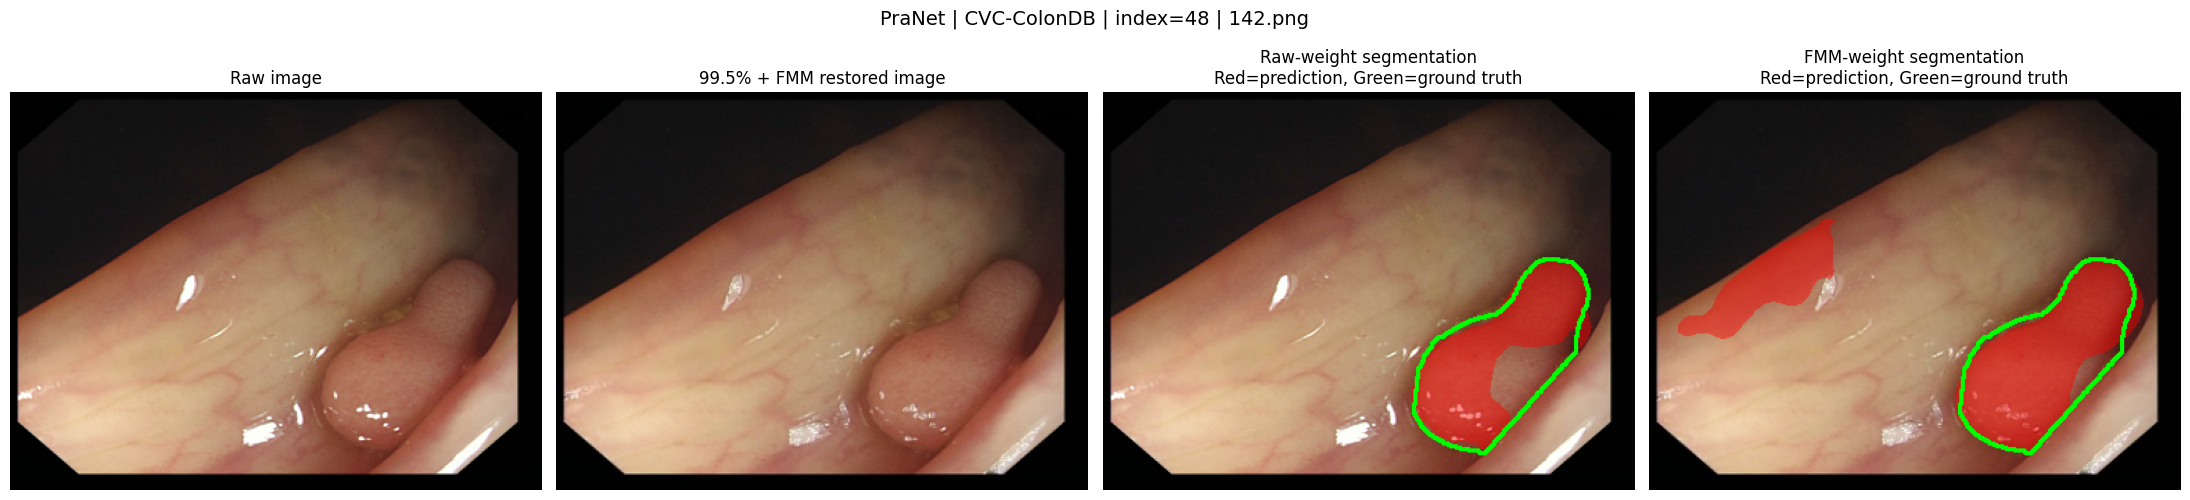

可视化使用评估缓存: 142.png


In [10]:
# =========================
# 可视化：直接使用表格评估时缓存的同一次前向结果
# =========================
import matplotlib.pyplot as plt

VIS_MASK_THRESHOLD = PREDICTION_THRESHOLD


def make_segmentation_overlay(image_rgb, prediction, ground_truth):
    """预测区域显示为红色，真实Mask边界显示为绿色。"""
    canvas = np.clip(image_rgb * 255.0, 0, 255).astype(np.uint8).copy()
    predicted_mask = np.asarray(prediction).squeeze() >= VIS_MASK_THRESHOLD
    ground_truth_mask = (np.asarray(ground_truth).squeeze() >= 0.5).astype(np.uint8)

    red = np.array([255, 0, 0], dtype=np.float32)
    canvas[predicted_mask] = (
        0.55 * canvas[predicted_mask].astype(np.float32) + 0.45 * red
    ).astype(np.uint8)

    contours, _ = cv2.findContours(
        ground_truth_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    cv2.drawContours(canvas, contours, -1, (0, 255, 0), 2)
    return canvas


def visualize_raw_vs_fmm():
    required = {"raw", "fmm"}
    if set(VISUALIZATION_CACHE) != required:
        raise RuntimeError("可视化缓存不完整，请先运行上方完整评估单元")

    raw_item = VISUALIZATION_CACHE["raw"]
    fmm_item = VISUALIZATION_CACHE["fmm"]
    if raw_item["name"] != fmm_item["name"]:
        raise RuntimeError("Raw与FMM可视化缓存对应的文件名不一致")

    raw_image = raw_item["image"]
    fmm_image = fmm_item["image"]
    ground_truth = raw_item["mask"]
    raw_prediction = raw_item["prediction"]
    fmm_prediction = fmm_item["prediction"]

    raw_overlay = make_segmentation_overlay(raw_image, raw_prediction, ground_truth)
    fmm_overlay = make_segmentation_overlay(fmm_image, fmm_prediction, ground_truth)

    figure, axes = plt.subplots(1, 4, figsize=(22, 5.5))
    panels = [
        (raw_image, "Raw image"),
        (fmm_image, "99.5% + FMM restored image"),
        (raw_overlay, "Raw-weight segmentation\nRed=prediction, Green=ground truth"),
        (fmm_overlay, "FMM-weight segmentation\nRed=prediction, Green=ground truth"),
    ]
    for axis, (panel, title) in zip(axes, panels):
        axis.imshow(panel)
        axis.set_title(title)
        axis.axis("off")

    figure.suptitle(
        f"{MODEL_NAME} | {VIS_DATASET} | index={VIS_SAMPLE_INDEX} | {raw_item['name']}",
        fontsize=14,
    )
    plt.tight_layout()
    plt.show()
    print("可视化使用评估缓存:", raw_item["name"])


visualize_raw_vs_fmm()
